In [ ]:
import time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

roll_num = "M26CPS001"
seed = int("".join([c for c in roll_num if c.isdigit()]))    # Igore alphabets and convert to integer

In [ ]:
# load Datset

faces_df = fetch_olivetti_faces(shuffle= False)              # shuffle= False : images of the same person grouped.

X = faces_df.data
y = faces_df.target

print("Dataset shape = ", X.shape)
print("Labels shape = ", y.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset shape =  (400, 4096)
Labels shape =  (400,)


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving person_data.npz to person_data.npz


In [ ]:
# load split

split = np.load("person_data.npz")

train_index = split["train_index"]
val_index = split["val_index"]
test_index = split["test_index"]

# Create the datasets

X_train = X[train_index]
y_train = y[train_index]

X_val = X[val_index]
y_val = y[val_index]

X_test = X[test_index]
y_test = y[test_index]

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (240, 4096)
Validation set: (80, 4096)
Test set: (80, 4096)


Second test set: Created by setting the central \(16 \times 16\) block (rows and columns 24–39) of the original flattened \(64 X 64) image to zero.

In [ ]:
"""
    X_test previously of shape(80, 4096)
    creating seprate copy for masking of shape (80, 64, 64) where mask applied on rows and columns at 24 to 39, to zero.
"""
X_test_masked = X_test.reshape(80, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0

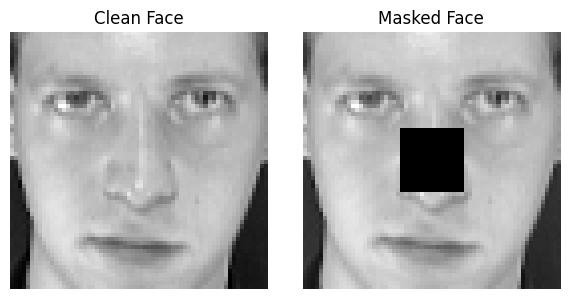

In [ ]:
# Display one original and masked face
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X_test[0].reshape(64, 64), cmap='gray')
axes[0].set_title("Clean Face")
axes[1].imshow(X_test_masked[0], cmap='gray')
axes[1].set_title("Masked Face")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("clean_vs_masked.pdf", bbox_inches="tight")
plt.show()

In [ ]:
depth_values = [2, 4, 8, 16, None]
leaf_values = [1, 2, 4]

best_val_acc = -1
best_tree = None
best_depth = None
best_leaf = None

results = []

# trying 15 combinations of different depth and leaf value
for d in depth_values:
    for l in leaf_values:
        tree =  DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, random_state=seed)
        tree.fit(X_train, y_train)
        prediction = tree.predict(X_val)
        tree_acc = accuracy_score(y_val, prediction)

        results.append((d, l, tree_acc))
        print("Depth:", d, "Min leaf:", l, "Validation accuracy:", round(tree_acc, 4))

        # Storing best validation model
        if tree_acc > best_val_acc:
            best_val_acc = tree_acc
            best_tree = tree          # Best Tree model allready stored
            best_depth = d
            best_leaf = l

print("\nBest depth:", best_depth)
print("Best minimum leaf samples:", best_leaf)
print("Best validation accuracy:", round(best_val_acc, 4))

Depth: 2 Min leaf: 1 Validation accuracy: 0.0625
Depth: 2 Min leaf: 2 Validation accuracy: 0.0625
Depth: 2 Min leaf: 4 Validation accuracy: 0.0625
Depth: 4 Min leaf: 1 Validation accuracy: 0.1125
Depth: 4 Min leaf: 2 Validation accuracy: 0.1125
Depth: 4 Min leaf: 4 Validation accuracy: 0.1125
Depth: 8 Min leaf: 1 Validation accuracy: 0.1875
Depth: 8 Min leaf: 2 Validation accuracy: 0.1875
Depth: 8 Min leaf: 4 Validation accuracy: 0.1875
Depth: 16 Min leaf: 1 Validation accuracy: 0.3375
Depth: 16 Min leaf: 2 Validation accuracy: 0.3375
Depth: 16 Min leaf: 4 Validation accuracy: 0.3375
Depth: None Min leaf: 1 Validation accuracy: 0.6875
Depth: None Min leaf: 2 Validation accuracy: 0.65
Depth: None Min leaf: 4 Validation accuracy: 0.6625

Best depth: None
Best minimum leaf samples: 1
Best validation accuracy: 0.6875


In [ ]:
# Evaluation

# Predictions
train_pred = best_tree.predict(X_train)
val_pred = best_tree.predict(X_val)
test_pred = best_tree.predict(X_test)

# Accuracies
train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)
test_acc = accuracy_score(y_test, test_pred)

# Leaf statistics
number_of_leaves = best_tree.get_n_leaves()                             # Total leaves in selected tree
mean_samples_per_leaf = X_train.shape[0]/number_of_leaves               # Mean samples per leaf = total images ÷ number of leaves.
counts = pd.Series(best_tree.apply(X_train)).value_counts()
single_sample_leaves = (counts == 1).sum()
single_sample_leaves_fraction = single_sample_leaves/number_of_leaves   #leaves containing only one training example

print("\n--- Selected Decision Tree ---")
print("Depth:", best_tree.get_depth())
print("Number of leaves:", number_of_leaves)
print("Mean samples per leaf:", round(mean_samples_per_leaf, 2))
print("Leaves containing one training image:", single_sample_leaves)
print("Fraction of single-sample leaves:",
      round(single_sample_leaves_fraction, 4))

print("\nTrain accuracy:", round(train_acc, 4))
print("Validation accuracy:", round(val_acc, 4))
print("Test accuracy:", round(test_acc, 4))


--- Selected Decision Tree ---
Depth: 34
Number of leaves: 45
Mean samples per leaf: 5.33
Leaves containing one training image: 5
Fraction of single-sample leaves: 0.1111

Train accuracy: 1.0
Validation accuracy: 0.6875
Test accuracy: 0.55


In [ ]:
df = pd.DataFrame(columns=[["Depth", "Leaf Sample", "Accuracy"]], data=results)
print(df)

os.makedirs("que1_results", exist_ok=True)
df.to_csv("que1_results/depth_leaf_accuracy.csv", index=False)

   Depth Leaf Sample Accuracy
0    2.0           1   0.0625
1    2.0           2   0.0625
2    2.0           4   0.0625
3    4.0           1   0.1125
4    4.0           2   0.1125
5    4.0           4   0.1125
6    8.0           1   0.1875
7    8.0           2   0.1875
8    8.0           4   0.1875
9   16.0           1   0.3375
10  16.0           2   0.3375
11  16.0           4   0.3375
12   NaN           1   0.6875
13   NaN           2   0.6500
14   NaN           4   0.6625


**Changes as depth increases**

As the maximum depth of the decision tree increases, validation accuracy generally improves. At depth 2, the accuracy is only 6.25%, whereas at depth 16, it rises to 27.5%. The highest accuracy, 61.25%, is achieved with unlimited depth and a minimum leaf size of 1. This suggests that deeper trees can capture more complex patterns in face images. However, increasing the minimum number of samples required in a leaf causes a slight reduction in accuracy.
1(b). Implementing Bagging from Scratch
Implement bootstrap aggregation (bagging) manually using bootstrap samples of the same size as the original training set. Use the fixed decision tree configuration selected in Part (a). Evaluate the ensemble for \(B \in \{1,5,10,25,50,100,200\}\), reporting training, validation, and test accuracy, as well as the average number of unique training examples in each bootstrap sample. Compare the observed average with its theoretical expectation.

Procedure:

1. Generate bootstrap samples: Randomly draw 240 images from the original training set of 240 images, allowing repeated selections. Consequently, some images may appear multiple times, while others may not be selected.

2. Train individual trees: Fit a decision tree on each bootstrap sample using the fixed hyperparameters chosen in Part (a).

3. Build the ensemble: Train 200 trees once and reuse the first \(B\) trees for each required ensemble size. This avoids retraining trees for every value of \(B\).

4. Make predictions by majority voting: For each image, collect predictions from the selected trees and assign the class receiving the most votes.

5. Evaluate performance: For each ensemble size, calculate training, validation, and test accuracy. Also, compute the average number of distinct training examples per bootstrap sample and compare it with the theoretical expectation.

**Theoretical expectation**

For a training set containing 240 images, each bootstrap sample is expected to contain approximately 152 distinct training examples, which is about 63.3% of the original training set. The remaining images are either not selected or appear multiple times in the sample.

In [ ]:
# Implement bagging from scratch

n = len(X_train)                          # no. of training images
bag_rng = np.random.default_rng(seed+1)   # Separate random generator for bagging
trees = []
bootstrap_samples = []
distinct_counts = []

for i in range(200):                                               # Train 200 trees, one at a time
    sample_index = bag_rng.choice(n, size=n, replace=True)         # Randomly select n indices with replacement
    distinct_count = len(np.unique(sample_index))                  # Count unique training images in current sample

    # Create a new tree with the frozen settings
    tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=seed + i)

    # Train using the bootstrap sample
    tree.fit(X_train[sample_index], y_train[sample_index])

    # Save the tree and sample information
    trees.append(tree)
    bootstrap_samples.append(sample_index)
    distinct_counts.append(distinct_count)

print("Total trees trained:", len(trees))
print("First bootstrap sample size:", len(bootstrap_samples[0]))
print("Distinct images in first sample:", distinct_counts[0])

Total trees trained: 200
First bootstrap sample size: 240
Distinct images in first sample: 157


Each bootstrap sample has 240 selections, but the number of distinct images is usually smaller than 240

In [ ]:
# Majority voting function

def bagging_predict(X_data, trees):
    # One row for each image and one column for each label/persosn
    votes = np.zeros((len(X_data),40), dtype=int)

    # get predictions from every given tree
    for tree in trees:
        predictions = tree.predict(X_data).astype(int)       # prediction will be used as index so int type

        # Add one vote to the predicted label/identity
        for i in range(len(predictions)):
            votes[i, predictions[i]] += 1

    # Select the identity with the highest number of votes
    final_predictions = np.argmax(votes, axis=1)

    return final_predictions, votes

In [ ]:
#Sample running

final_predictions, votes = bagging_predict(X_test, trees[:20])
final_predictions, votes

(array([ 7,  0,  1,  1,  2,  2,  3,  3,  4,  4,  5,  5, 35,  6,  7,  7,  9,
         8, 26,  9, 10, 10,  8, 11, 12,  1, 20, 13, 14,  3,  5, 15, 16, 16,
        17, 17, 18, 18, 19, 19, 20, 20, 21, 21, 22, 22, 23, 23, 24, 24, 25,
         2, 26, 26, 27,  3, 28, 28, 29, 29, 20, 20, 31, 31, 32, 32, 33, 33,
         8, 34, 14, 35, 36,  2, 37, 37, 38, 38, 17, 39]),
 array([[ 2,  0,  0, ...,  0,  0,  0],
        [ 9,  0,  0, ...,  1,  0,  0],
        [ 0, 10,  0, ...,  0,  0,  0],
        ...,
        [ 0,  1,  0, ...,  0,  5,  0],
        [ 2,  0,  2, ...,  0,  0,  2],
        [ 0,  0,  3, ...,  2,  0,  6]]))

In [ ]:
print(votes[0])    # for image index 0 shows predictions from 20 trees

[2 0 0 0 1 0 0 6 1 0 0 0 0 0 0 2 0 1 0 0 1 0 0 1 0 1 3 0 0 0 0 1 0 0 0 0 0
 0 0 0]


In [ ]:
np.argmax(votes, axis=1)

array([ 7,  0,  1,  1,  2,  2,  3,  3,  4,  4,  5,  5, 35,  6,  7,  7,  9,
        8, 26,  9, 10, 10,  8, 11, 12,  1, 20, 13, 14,  3,  5, 15, 16, 16,
       17, 17, 18, 18, 19, 19, 20, 20, 21, 21, 22, 22, 23, 23, 24, 24, 25,
        2, 26, 26, 27,  3, 28, 28, 29, 29, 20, 20, 31, 31, 32, 32, 33, 33,
        8, 34, 14, 35, 36,  2, 37, 37, 38, 38, 17, 39])

For each image, the class receiving the highest number of votes is selected as the final prediction. For example, image 9 receives the maximum of 6 votes for class label 7, so the predicted label for that image is 7.

In [ ]:
# Evaluate every ensemble size

B_values = [1, 5, 10, 25, 50, 100, 200]
bagging_results = []

for B in B_values:
    current_trees = trees[:B]             # using first B values

     # Predictions on all three datasets
    train_pred, train_votes = bagging_predict(X_train, current_trees)
    val_pred, val_votes = bagging_predict(X_val, current_trees)
    test_pred, test_votes = bagging_predict(X_test, current_trees)

    # Calculate accuracy
    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)
    test_acc = accuracy_score(y_test, test_pred)

    # Average number of distinct images per bootstrap sample
    avg_distinct = np.mean(distinct_counts[:B])

    # Save results
    bagging_results.append({"B": B, "Train Accuracy": train_acc, "Validation Accuracy": val_acc, "Test Accuracy": test_acc, "Average Distinct Images": avg_distinct})

    print("\nNumber of trees:", B)
    print("Train accuracy:", round(train_acc, 4))
    print("Validation accuracy:", round(val_acc, 4))
    print("Test accuracy:", round(test_acc, 4))
    print("Average distinct images:", round(avg_distinct, 2))


Number of trees: 1
Train accuracy: 0.775
Validation accuracy: 0.3625
Test accuracy: 0.3875
Average distinct images: 157.0

Number of trees: 5
Train accuracy: 0.95
Validation accuracy: 0.5375
Test accuracy: 0.5875
Average distinct images: 152.6

Number of trees: 10
Train accuracy: 0.9958
Validation accuracy: 0.775
Test accuracy: 0.7125
Average distinct images: 152.2

Number of trees: 25
Train accuracy: 1.0
Validation accuracy: 0.825
Test accuracy: 0.8375
Average distinct images: 151.92

Number of trees: 50
Train accuracy: 1.0
Validation accuracy: 0.875
Test accuracy: 0.85
Average distinct images: 151.46

Number of trees: 100
Train accuracy: 1.0
Validation accuracy: 0.875
Test accuracy: 0.8625
Average distinct images: 151.85

Number of trees: 200
Train accuracy: 1.0
Validation accuracy: 0.9
Test accuracy: 0.9
Average distinct images: 151.63


In [ ]:
# Theoretical expected number of distinct images
expected_distinct = n * (1 - (1 - 1/n) ** n)            # expected number of distinct images

print("Original training images:", n)
print("Theoretical expected distinct images:",round(expected_distinct, 2))
print("Theoretical percentage:",round(expected_distinct / n * 100, 2), "%")

# Show the measured averages
for result in bagging_results:
    print("B =  ", result["B"], "\t| Measured =", round(result["Average Distinct Images"], 2),"\t| Theoretical =", round(expected_distinct, 2))

Original training images: 240
Theoretical expected distinct images: 151.89
Theoretical percentage: 63.29 %
B =   1 	| Measured = 157.0 	| Theoretical = 151.89
B =   5 	| Measured = 152.6 	| Theoretical = 151.89
B =   10 	| Measured = 152.2 	| Theoretical = 151.89
B =   25 	| Measured = 151.92 	| Theoretical = 151.89
B =   50 	| Measured = 151.46 	| Theoretical = 151.89
B =   100 	| Measured = 151.85 	| Theoretical = 151.89
B =   200 	| Measured = 151.63 	| Theoretical = 151.89


In [ ]:
results_df = pd.DataFrame(bagging_results)
results_df.to_csv("que1_results/BaggingResults.csv", index=False)

**1(c). Evaluation of Bagging Performance**

For each ensemble size \\(B\\), calculate the out-of-bag (OOB) accuracy, the average pairwise disagreement between decision trees, and the mean vote margin. Plot each metric against \\(B\\) to observe how ensemble performance changes as more trees are added.

The vote margin is defined as the difference between the fraction of votes received by the most frequently predicted class and the fraction received by the second-most frequently predicted class.

Select the final ensemble size based on validation accuracy and justify the choice. Finally, compare the trends in OOB accuracy, pairwise disagreement, and vote margin to determine whether these metrics provide consistent conclusions about the ensemble's performance.

In [ ]:
# Calculate all metrics

# Store the results for each B
oob_accuracies = []
pairwise_disagreements = []
mean_vote_margins = []

n = len(X_train)

# Predict each training image with every tree only once
train_tree_preds = np.array([
    tree.predict(X_train).astype(int) for tree in trees
])

# Find which training images were NOT used by each tree
oob_masks = []

for i in range(len(trees)):
    in_bag = np.zeros(n, dtype=bool)
    in_bag[bootstrap_samples[i]] = True
    oob_masks.append(~in_bag)

oob_masks = np.array(oob_masks)

# Evaluate each ensemble size
for B in B_values:

    # ---------------------------------
    # 1. Out-of-bag (OOB) accuracy
    # ---------------------------------
    oob_votes = np.zeros((n, 40), dtype=int)
    oob_counts = np.zeros(n, dtype=int)

    for i in range(B):
        mask = oob_masks[i]
        image_indices = np.where(mask)[0]
        predictions = train_tree_preds[i, mask]

        oob_votes[image_indices, predictions] += 1
        oob_counts[image_indices] += 1

    # Keep images that received at least one OOB prediction
    valid = oob_counts > 0
    oob_pred = np.argmax(oob_votes[valid], axis=1)
    oob_acc = accuracy_score(y_train[valid], oob_pred)
    oob_accuracies.append(oob_acc)

    # ---------------------------------
    # 2. Pairwise disagreement
    # Use validation images
    # ---------------------------------
    current_trees = trees[:B]

    val_predictions = np.array([
        tree.predict(X_val).astype(int)
        for tree in current_trees
    ])

    if B > 1:
        # Count votes for each identity on each validation image
        val_votes = np.zeros((len(X_val), 40), dtype=int)

        for i in range(B):
            for j in range(len(X_val)):
                val_votes[j, val_predictions[i, j]] += 1

        # Number of tree pairs agreeing on each image
        same_pairs = np.sum(val_votes * (val_votes - 1) / 2, axis=1)

        total_pairs = B * (B - 1) / 2

        disagreement = np.mean(1 - same_pairs / total_pairs)
    else:
        # No tree pairs exist when B = 1
        disagreement = np.nan

    pairwise_disagreements.append(disagreement)

    # ---------------------------------
    # 3. Mean vote margin
    # ---------------------------------
    val_pred, val_votes = bagging_predict(X_val, current_trees)

    sorted_votes = np.sort(val_votes, axis=1)

    winning_fraction = sorted_votes[:, -1] / B
    runner_up_fraction = sorted_votes[:, -2] / B

    margins = winning_fraction - runner_up_fraction
    mean_margin = np.mean(margins)

    mean_vote_margins.append(mean_margin)

    print(
        f"B={B:3d} | "
        f"OOB Accuracy={oob_acc:.4f} | "
        f"Disagreement={disagreement:.4f} | "
        f"Mean Vote Margin={mean_margin:.4f}"
    )

B=  1 | OOB Accuracy=0.3494 | Disagreement=nan | Mean Vote Margin=1.0000
B=  5 | OOB Accuracy=0.3037 | Disagreement=0.7850 | Mean Vote Margin=0.2475
B= 10 | OOB Accuracy=0.3686 | Disagreement=0.7681 | Mean Vote Margin=0.2750
B= 25 | OOB Accuracy=0.5833 | Disagreement=0.7693 | Mean Vote Margin=0.2960
B= 50 | OOB Accuracy=0.6833 | Disagreement=0.7795 | Mean Vote Margin=0.2928
B=100 | OOB Accuracy=0.7417 | Disagreement=0.7732 | Mean Vote Margin=0.2981
B=200 | OOB Accuracy=0.7750 | Disagreement=0.7733 | Mean Vote Margin=0.3024


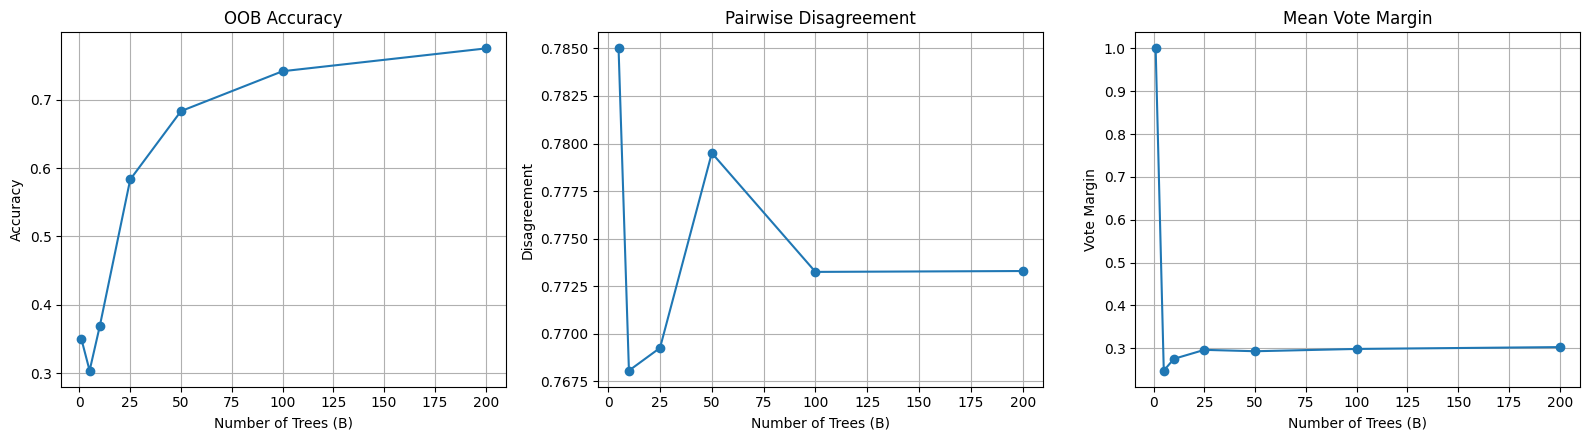

In [ ]:
# Plot all three metrics against \(B\)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(B_values, oob_accuracies, marker="o")
axes[0].set_title("OOB Accuracy")
axes[0].set_xlabel("Number of Trees (B)")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True)

axes[1].plot(B_values, pairwise_disagreements, marker="o")
axes[1].set_title("Pairwise Disagreement")
axes[1].set_xlabel("Number of Trees (B)")
axes[1].set_ylabel("Disagreement")
axes[1].grid(True)

axes[2].plot(B_values, mean_vote_margins, marker="o")
axes[2].set_title("Mean Vote Margin")
axes[2].set_xlabel("Number of Trees (B)")
axes[2].set_ylabel("Vote Margin")
axes[2].grid(True)

plt.tight_layout()
plt.savefig("que1_results/bagging_metrics_vs_B.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Select the final ensemble using validation accuracy

best_result = max(
    bagging_results,
    key=lambda result: result["Validation Accuracy"]
)

final_B = best_result["B"]

print("Selected ensemble size:", final_B)
print("Validation accuracy:", best_result["Validation Accuracy"])
print("OOB accuracy:", oob_accuracies[B_values.index(final_B)])
print("Pairwise disagreement:",
      pairwise_disagreements[B_values.index(final_B)])
print("Mean vote margin:",
      mean_vote_margins[B_values.index(final_B)])

Selected ensemble size: 200
Validation accuracy: 0.9
OOB accuracy: 0.775
Pairwise disagreement: 0.7732933417085428
Mean vote margin: 0.3024375


1(d). Comparison of the Single Decision Tree and Bagging Models

Evaluate the fixed single decision tree and the final bagging ensemble on both the clean and masked test sets. Report the accuracy and prediction confidence of each model to compare their performance under normal and partially obscured image conditions.

Identify two test images for which bagging produces the correct prediction while the single tree makes an incorrect prediction, and two images for which both models fail. For each selected image, present the true label, the single tree's prediction, and the bagging ensemble's vote counts.

Use these examples to explain how bagging can reduce errors caused by the instability of individual decision trees by combining predictions from multiple models. Also, discuss its limitations, particularly when the image contains insufficient distinguishing information or when multiple trees make similar incorrect predictions.

In [ ]:
# tree for final B value
final_trees = trees[:final_B]

# Get predictions and votes for clean test images
tree_clean_pred = best_tree.predict(X_test).astype(int)
tree_clean_conf = np.max(best_tree.predict_proba(X_test), axis=1)

bag_clean_pred, bag_clean_votes = bagging_predict(X_test, final_trees)
bag_clean_conf = np.max(bag_clean_votes, axis=1) / final_B


# Get predictions and votes for masked test images
tree_masked_pred = best_tree.predict(X_test_masked.reshape(80, 4096)).astype(int)
tree_masked_conf = np.max(best_tree.predict_proba(X_test_masked.reshape(80, 4096)), axis=1)

bag_masked_pred, bag_masked_votes = bagging_predict(X_test_masked.reshape(80, 4096), final_trees)
bag_masked_conf = np.max(bag_masked_votes, axis=1) / final_B

In [ ]:
# Print accuracy and mean confidence
comparison = [
    ("Single Tree", "Clean", y_test, tree_clean_pred, tree_clean_conf),
    ("Bagging", "Clean", y_test, bag_clean_pred, bag_clean_conf),
    ("Single Tree", "Masked", y_test, tree_masked_pred, tree_masked_conf),
    ("Bagging", "Masked", y_test, bag_masked_pred, bag_masked_conf)
]

print(f"{'Model':<15} {'Test Set':<10} {'Accuracy':<12} {'Mean Confidence':<16}")

res = []

for model, test_type, true_y, pred, conf in comparison:
    acc = accuracy_score(true_y, pred)
    print(f"{model:<15} {test_type:<10} {acc:<12.4f} {np.mean(conf):<16.4f}")

    res.append({"Model": model, "Test Set": test_type, "Accuracy": acc,"Mean Confidence": np.mean(conf)})
    results_df = pd.DataFrame(res)
    results_df.to_csv("que1_results/tree_bagging_clean_masked.csv", index=False)

Model           Test Set   Accuracy     Mean Confidence 
Single Tree     Clean      0.5500       1.0000          
Bagging         Clean      0.9000       0.3893          
Single Tree     Masked     0.5500       1.0000          
Bagging         Masked     0.7375       0.2851          


**2nd Question**

2a

In [ ]:
import numpy as np

# 9 samples belonging to 3 classes
y_true = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

# Predictions made by one weak learner (decision tree)
y_pred = np.array([0, 0, 1, 1, 2, 1, 2, 0, 2])

n = len(y_true)
K = 3

# Step 1: Initialize equal sample weights
weights = np.ones(n) / n

print("Initial sample weights:")
print(np.round(weights, 4))

# Step 2: Find incorrect predictions
incorrect = (y_true != y_pred)               # whichever are diff are marked True i.e incorrect

print("\nTrue labels:       ", y_true)
print("Weak predictions:  ", y_pred)
print("Incorrect samples: ", incorrect)

# Step 3: Calculate weighted classification error
error = np.sum(weights[incorrect])

print("\nWeighted error:", round(error, 4))

# Step 4: Check if the learner is better than random
random_error = 1 - (1 / K)

if error >= random_error:
    print("Weak learner is not better than random prediction.")
    print("Stop boosting: do not use this learner.")
else:
    # Step 5: Calculate SAMME learner weight      --> AdaBoost for more than 2 classes.
    alpha = np.log((1 - error) / error) + np.log(K - 1)

    print("Learner weight (alpha):", round(alpha, 4))

    # Step 6: Update sample weights
    # Incorrect samples receive increased weights
    weights[incorrect] *= np.exp(alpha)

    # Step 7: Normalize so weights sum to 1
    weights = weights / np.sum(weights)

    print("\nUpdated normalized sample weights:")
    print(np.round(weights, 4))

    print("\nSum of updated weights:", round(np.sum(weights), 4))

Initial sample weights:
[0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]

True labels:        [0 0 0 1 1 1 2 2 2]
Weak predictions:   [0 0 1 1 2 1 2 0 2]
Incorrect samples:  [False False  True False  True False False  True False]

Weighted error: 0.3333
Learner weight (alpha): 1.3863

Updated normalized sample weights:
[0.0556 0.0556 0.2222 0.0556 0.2222 0.0556 0.0556 0.2222 0.0556]

Sum of updated weights: 1.0


**2b**

In [ ]:
# SAMME implementation
def train_samme(X_train, y_train, X_val, y_val, depth, rounds, seed):
    n = len(X_train)

    # Number of face identities computed from the passed training targets
    K = len(np.unique(y_train))

    # Start with equal weights for all training images
    sample_weights = np.ones(n) / n

    models = []
    alphas = []

    # Save metrics after each boosting round
    weighted_errors = []
    max_sample_weights = []
    top10_weights = []

    classes = np.unique(y_train)

    for t in range(rounds):

        # Train one decision tree using current sample weights
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        tree.fit(X_train, y_train, sample_weight=sample_weights)

        # Predictions on the training images
        train_pred = tree.predict(X_train)

        # Calculate weighted classification error
        incorrect = (train_pred != y_train)
        error = np.sum(sample_weights[incorrect])

         # A weak learner must perform better than random guessing
        random_error = 1 - (1 / K)

        if error >= random_error:
            print(
                f"Depth {depth}, round {t + 1}: "
                "weak learner is no better than random. Stopping."
            )
            break

        # Avoid taking log(0) if a tree classifies every sample correctly
        if error <= 1e-10:
            alpha = np.log((1 - 1e-10) / 1e-10) + np.log(K - 1)
        else:
            alpha = np.log((1 - error) / error) + np.log(K - 1)

        # Save the learner and its weight
        models.append(tree)
        alphas.append(alpha)
        weighted_errors.append(error)

        # Increase weights of incorrectly classified images
        sample_weights[incorrect] *= np.exp(alpha)

        # Normalize sample weights so that they sum to 1
        sample_weights = sample_weights / np.sum(sample_weights)

        # Save weight statistics after the update
        max_sample_weights.append(np.max(sample_weights))

        sorted_weights = np.sort(sample_weights)
        top10_weights.append(np.sum(sorted_weights[-10:]))

               # Stop if this tree perfectly classifies the training set
        if error <= 1e-10:
            print(f"Depth {depth}: perfect training classification at round {t + 1}.")
            break

    return {
        "models": models,
        "alphas": np.array(alphas),
        "weighted_errors": np.array(weighted_errors),
        "max_sample_weights": np.array(max_sample_weights),
        "top10_weights": np.array(top10_weights),
        "depth": depth,
        "requested_rounds": rounds,
        "classes": classes
    }


# Predict using weighted SAMME votes
def samme_predict(X, model):
    classes = model["classes"]
    scores = np.zeros((len(X), len(classes)))

    for tree, alpha in zip(model["models"], model["alphas"]):
        predictions = tree.predict(X)

        for j, class_label in enumerate(classes):
            scores[:, j] += alpha * (predictions == class_label)

    predictions = classes[np.argmax(scores, axis=1)]
    return predictions, scores

In [ ]:
import time

# Try all combinations of depth and boosting rounds
depth_values = [1, 2, 3, 4]
round_values = [10, 25, 50, 100]

samme_results = []
best_samme = None
best_val_acc = -1

for depth in depth_values:
    for rounds in round_values:

        start_time = time.time()

        model = train_samme(
            X_train, y_train,
            X_val, y_val,
            depth=depth,
            rounds=rounds,
            seed=seed + depth * 1000 + rounds
        )

        val_pred, val_scores = samme_predict(X_val, model)
        val_acc = accuracy_score(y_val, val_pred)
        elapsed = time.time() - start_time

        result = {
            "Depth": depth,
            "Requested Rounds": rounds,
            "Actual Rounds": len(model["models"]),
            "Validation Accuracy": val_acc,
            "Training Time (s)": elapsed,
            "Model": model
        }

        samme_results.append(result)

        print(
            f"Depth={depth}, Requested rounds={rounds}, "
            f"Actual rounds={len(model['models'])}, "
            f"Validation accuracy={val_acc:.4f}, "
            f"Time={elapsed:.2f}s"
        )

        # Select using clean validation accuracy only
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_samme = model

print("\nSelected depth:", best_samme["depth"])
print("Selected actual rounds:", len(best_samme["models"]))
print("Best validation accuracy:", round(best_val_acc, 4))

Depth=1, Requested rounds=10, Actual rounds=10, Validation accuracy=0.0500, Time=2.12s
Depth=1, Requested rounds=25, Actual rounds=25, Validation accuracy=0.0625, Time=4.72s
Depth=1, Requested rounds=50, Actual rounds=50, Validation accuracy=0.1750, Time=8.88s
Depth=1, Requested rounds=100, Actual rounds=100, Validation accuracy=0.1500, Time=18.18s
Depth=2, Requested rounds=10, Actual rounds=10, Validation accuracy=0.0750, Time=3.29s
Depth=2, Requested rounds=25, Actual rounds=25, Validation accuracy=0.1500, Time=9.28s
Depth=2, Requested rounds=50, Actual rounds=50, Validation accuracy=0.1875, Time=17.58s
Depth=2, Requested rounds=100, Actual rounds=100, Validation accuracy=0.2250, Time=36.29s
Depth=3, Requested rounds=10, Actual rounds=10, Validation accuracy=0.1750, Time=4.97s
Depth=3, Requested rounds=25, Actual rounds=25, Validation accuracy=0.2250, Time=13.36s
Depth=3, Requested rounds=50, Actual rounds=50, Validation accuracy=0.3750, Time=27.11s
Depth=3, Requested rounds=100, Act

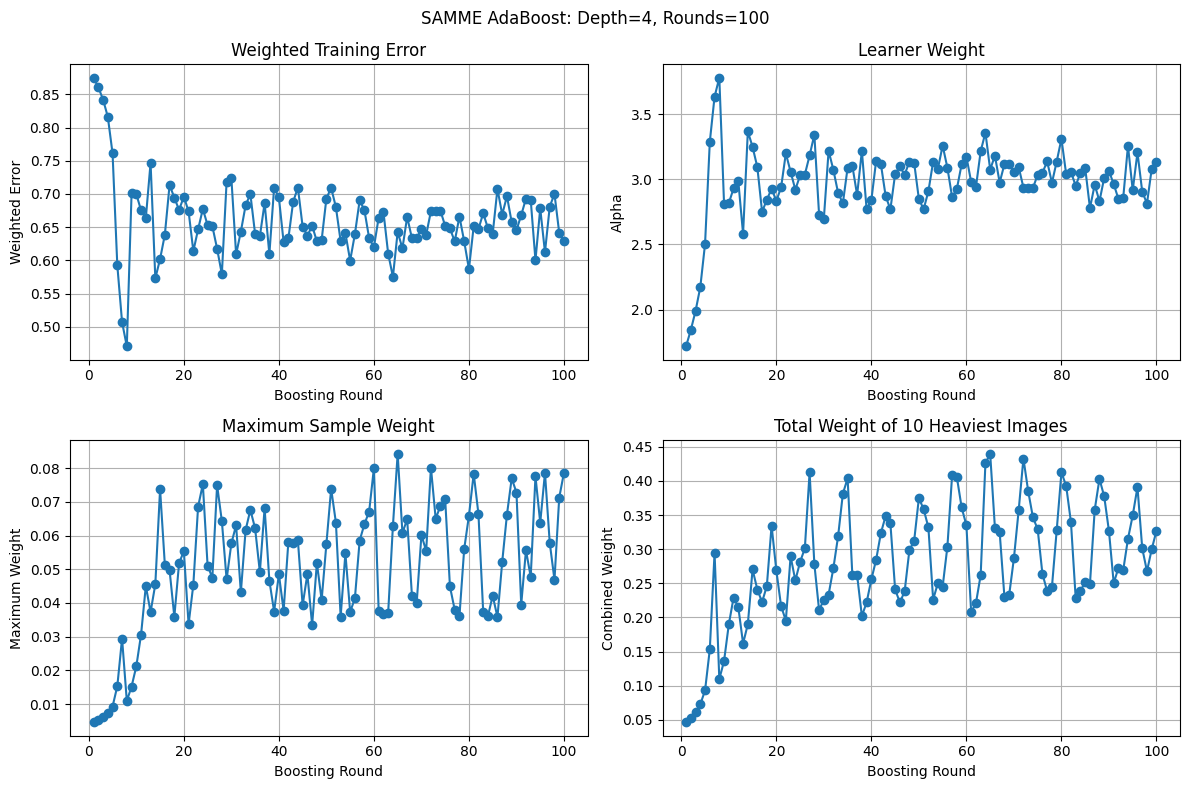

In [ ]:
rounds = range(1, len(best_samme["models"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Weighted training error
axes[0, 0].plot(
    rounds, best_samme["weighted_errors"], marker="o"
)
axes[0, 0].set_title("Weighted Training Error")
axes[0, 0].set_xlabel("Boosting Round")
axes[0, 0].set_ylabel("Weighted Error")
axes[0, 0].grid(True)

# 2. Learner weight (alpha)
axes[0, 1].plot(
    rounds, best_samme["alphas"], marker="o"
)
axes[0, 1].set_title("Learner Weight")
axes[0, 1].set_xlabel("Boosting Round")
axes[0, 1].set_ylabel("Alpha")
axes[0, 1].grid(True)

# 3. Maximum sample weight
axes[1, 0].plot(
    rounds, best_samme["max_sample_weights"], marker="o"
)
axes[1, 0].set_title("Maximum Sample Weight")
axes[1, 0].set_xlabel("Boosting Round")
axes[1, 0].set_ylabel("Maximum Weight")
axes[1, 0].grid(True)

# 4. Total weight of the 10 heaviest images
axes[1, 1].plot(
    rounds, best_samme["top10_weights"], marker="o"
)
axes[1, 1].set_title("Total Weight of 10 Heaviest Images")
axes[1, 1].set_xlabel("Boosting Round")
axes[1, 1].set_ylabel("Combined Weight")
axes[1, 1].grid(True)

plt.suptitle(
    f"SAMME AdaBoost: Depth={best_samme['depth']}, "
    f"Rounds={len(best_samme['models'])}"
)

os.makedirs("que2_results", exist_ok=True)
plt.tight_layout()
plt.savefig("que2_results/samme_diagnostics.pdf", bbox_inches="tight")
plt.show()

**2c**

In [ ]:
# Comparing bagging and boosting for 25, 50 and 100 learners
B_values_compare = [25, 50, 100]
comparison_results = []

for B in B_values_compare:

    # Train a fresh bagging model
    start = time.time()

    bag_trees = []
    bag_rng = np.random.default_rng(seed + B)

    for i in range(B):
        sample_idx = bag_rng.choice(len(X_train), size=len(X_train), replace=True)  #picks 240 random row numbers with repeats

        tree = DecisionTreeClassifier(max_depth=best_depth,min_samples_leaf=best_leaf,random_state=seed + i)
        tree.fit(X_train[sample_idx], y_train[sample_idx])
        bag_trees.append(tree)

    bag_time = time.time() - start

    # Bagging accuracy
    bag_train_pred, _ = bagging_predict(X_train, bag_trees)
    bag_val_pred, _ = bagging_predict(X_val, bag_trees)
    bag_test_pred, _ = bagging_predict(X_test, bag_trees)

    comparison_results.append({
        "Model": "Bagging",
        "Learners": B,
        "Train Accuracy": accuracy_score(y_train, bag_train_pred),
        "Validation Accuracy": accuracy_score(y_val, bag_val_pred),
        "Clean Test Accuracy": accuracy_score(y_test, bag_test_pred),
        "Training Time (s)": bag_time
    })
     # 2. Train a fresh boosting model for same B of Bagging
    start = time.time()

    boost_model = train_samme(
        X_train, y_train, X_val, y_val,
        depth=best_samme["depth"],
        rounds=B,
        seed=seed + 5000 + B
    )

    boost_time = time.time() - start

    # Boosting accuracy
    boost_train_pred, _ = samme_predict(X_train, boost_model)
    boost_val_pred, _ = samme_predict(X_val, boost_model)
    boost_test_pred, _ = samme_predict(X_test, boost_model)

    comparison_results.append({
        "Model": "Boosting",
        "Learners": B,
        "Train Accuracy": accuracy_score(y_train, boost_train_pred),
        "Validation Accuracy": accuracy_score(y_val, boost_val_pred),
        "Clean Test Accuracy": accuracy_score(y_test, boost_test_pred),
        "Training Time (s)": boost_time
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df.to_csv("que2_results/depth_leaf_accuracy.csv", index=False)
print(comparison_df.round(4).to_string(index=False))

   Model  Learners  Train Accuracy  Validation Accuracy  Clean Test Accuracy  Training Time (s)
 Bagging        25          1.0000               0.8125               0.8500            70.7776
Boosting        25          0.8250               0.5000               0.3125            18.0204
 Bagging        50          1.0000               0.8625               0.8625           137.8312
Boosting        50          0.9917               0.4500               0.5000            36.4282
 Bagging       100          1.0000               0.9125               0.9125           244.3493
Boosting       100          0.9958               0.5375               0.4250            72.2809


In [ ]:
# Freeze the selected models
final_bagged_trees = trees[:final_B]
final_boosting = best_samme

# ---------- Testing on clean dataset ----------

# Single tree baseline
tree_clean_pred = best_tree.predict(X_test).astype(int)
tree_clean_conf = np.max(best_tree.predict_proba(X_test), axis=1)

# Bagging
bag_clean_pred, bag_clean_votes = bagging_predict(X_test, final_bagged_trees)
bag_clean_conf = np.max(bag_clean_votes, axis=1) / len(final_bagged_trees)

# Boosting
boost_clean_pred, boost_clean_scores = samme_predict(X_test, final_boosting)
boost_total_alpha = np.sum(final_boosting["alphas"])
boost_clean_conf = np.max(boost_clean_scores, axis=1) / boost_total_alpha


# ---------- Testing on Masked Datasets ----------

tree_masked_pred = best_tree.predict(X_test_masked.reshape(80, 4096).astype(int))
tree_masked_conf = np.max(best_tree.predict_proba(X_test_masked.reshape(80, 4096)), axis=1)
bag_masked_pred, bag_masked_votes = bagging_predict(X_test_masked.reshape(80, 4096), final_bagged_trees)
bag_masked_conf = np.max(bag_masked_votes, axis=1) / len(final_bagged_trees)

boost_masked_pred, boost_masked_scores = samme_predict(X_test_masked.reshape(80, 4096), final_boosting)
boost_masked_conf = np.max(boost_masked_scores, axis=1) / boost_total_alpha

# ---------- Print comparison ----------

comparison = [
    ("Single Tree", "Clean", tree_clean_pred, tree_clean_conf),
    ("Single Tree", "Masked", tree_masked_pred, tree_masked_conf),
    ("Bagging", "Clean", bag_clean_pred, bag_clean_conf),
    ("Bagging", "Masked", bag_masked_pred, bag_masked_conf),
    ("Boosting", "Clean", boost_clean_pred, boost_clean_conf),
    ("Boosting", "Masked", boost_masked_pred, boost_masked_conf)
]

print(f"{'Model':<15} {'Test Set':<10} {'Accuracy':<12} {'Mean Confidence':<16}")

result = []
for model_name, test_type, pred, conf in comparison:
    acc = accuracy_score(y_test, pred)
    print(
        f"{model_name:<15} {test_type:<10} "
        f"{acc:<12.4f} {np.mean(conf):<16.4f}"
    )
    result.append({'Model': model_name, 'Test Set': test_type, 'Accuracy': acc, 'Mean Confidence':np.mean(conf)})

result_df = pd.DataFrame(result)
result_df.to_csv("que2_results/clean_masked.csv", index=False)

Model           Test Set   Accuracy     Mean Confidence 
Single Tree     Clean      0.5500       1.0000          
Single Tree     Masked     0.0250       1.0000          
Bagging         Clean      0.9000       0.3893          
Bagging         Masked     0.7375       0.2851          
Boosting        Clean      0.3500       0.1226          
Boosting        Masked     0.3750       0.1143          


Test image index: 0
True identity: 0

Single tree:
Clean prediction: 15
Masked prediction: 32

Bagging:
Clean prediction: 0
Masked prediction: 26
Clean votes: [40  0  5  4  5  2  2 31  2  2  3  1  3  2  1 20  1 16  0  1  2  0  3 13
  1  3 27  3  0  0  0  2  0  0  1  0  0  2  0  2]
Masked votes: [25  0  1  3  2  2  1 24  2  1  1  0  7 24  2 13  1  9  0  0  6  0  1 12
  0  3 27  5  1  0  2  1  0 14  0  3  0  2  4  1]

Boosting:
Clean prediction: 3
Masked prediction: 3
Clean weighted scores: [23.956  4.812 28.855 37.764 30.419  0.     0.     5.289  0.     2.505
  0.     0.    22.308  3.117  5.629 14.875  3.37  12.222  0.     2.906
 23.602  0.     8.883  3.051  8.94   3.037  6.007  2.964  0.     0.
  3.09   3.184  2.928  0.     6.021  3.118  0.     5.739  0.    19.504]

Masked weighted scores: [20.667  1.718 22.573 34.733 27.435  0.     0.     5.289  3.095  2.505
  0.     0.    22.308 18.679  5.629 11.811  0.    12.554  0.     0.
  9.134  0.     8.883  3.051  8.94   3.037 14.943 11.59   0.

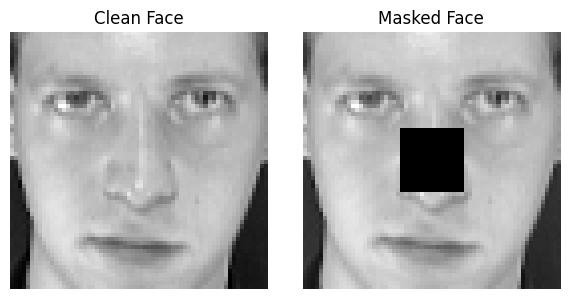

In [ ]:
# face where bagging and boosting respond differently to masking

# Case 1: One model changes its prediction; the other does
different_response = np.where(
    (
        (bag_clean_pred != bag_masked_pred) &       # bagging change prediction on clean and masked
        (boost_clean_pred == boost_masked_pred)     # bagging not change prediction on clean and masked
    ) |
    (
        (bag_clean_pred == bag_masked_pred) &
        (boost_clean_pred != boost_masked_pred)
    )
)[0]

# Case 2: Their predictions differ on the masked image
different_masked_predictions = np.where(
    bag_masked_pred != boost_masked_pred
)[0]

if len(different_response) > 0:                   # Part 1 has some faces
    face_idx = different_response[0]
elif len(different_masked_predictions) > 0:       # Part 2 has some faces
    face_idx = different_masked_predictions[0]
else:                                             # No facee found
    face_idx = None
    print("No test face found where the models respond differently.")

if face_idx is not None:
    print("Test image index:", face_idx)
    print("True identity:", y_test[face_idx])

    print("\nSingle tree:")
    print("Clean prediction:", tree_clean_pred[face_idx])
    print("Masked prediction:", tree_masked_pred[face_idx])

    print("\nBagging:")
    print("Clean prediction:", bag_clean_pred[face_idx])
    print("Masked prediction:", bag_masked_pred[face_idx])
    print("Clean votes:", bag_clean_votes[face_idx])
    print("Masked votes:", bag_masked_votes[face_idx])

    print("\nBoosting:")
    print("Clean prediction:", boost_clean_pred[face_idx])
    print("Masked prediction:", boost_masked_pred[face_idx])
    print("Clean weighted scores:", np.round(
        boost_clean_scores[face_idx], 3
    ))
    print("\nMasked weighted scores:", np.round(
        boost_masked_scores[face_idx], 3
    ))

    # Display the same face before and after masking
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))

    axes[0].imshow(X_test[face_idx].reshape(64, 64), cmap="gray")
    axes[0].set_title("Clean Face")

    axes[1].imshow(
        X_test_masked[face_idx].reshape(64, 64), cmap="gray"
    )
    axes[1].set_title("Masked Face")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig("que2_results/face_where_bagging_boosting_worked_differntly.pdf", bbox_inches="tight")
    plt.show()

**Results**

**For single tree**:Prediction for clean image is 15, where for masked image is 32

**For Bagging**:Prediction for clean image is 0, where for masked image is 26

**For Boosting**:Prediction for clean image is 3, where for masked image is 3

In [ ]:
# Examine tree disagreement for that face
"""
    printing how many bagging trees vote for each identity on the clean and masked image.
"""

if face_idx is not None:
    print("Bagging tree votes on clean image:")
    print({
        int(k): int(v)
        for k, v in enumerate(bag_clean_votes[face_idx])
        if v > 0
    })

    print("\nBagging tree votes on masked image:")
    print({
        int(k): int(v)
        for k, v in enumerate(bag_masked_votes[face_idx])
        if v > 0
    })

Bagging tree votes on clean image:
{0: 40, 2: 5, 3: 4, 4: 5, 5: 2, 6: 2, 7: 31, 8: 2, 9: 2, 10: 3, 11: 1, 12: 3, 13: 2, 14: 1, 15: 20, 16: 1, 17: 16, 19: 1, 20: 2, 22: 3, 23: 13, 24: 1, 25: 3, 26: 27, 27: 3, 31: 2, 34: 1, 37: 2, 39: 2}

Bagging tree votes on masked image:
{0: 25, 2: 1, 3: 3, 4: 2, 5: 2, 6: 1, 7: 24, 8: 2, 9: 1, 10: 1, 12: 7, 13: 24, 14: 2, 15: 13, 16: 1, 17: 9, 20: 6, 22: 1, 23: 12, 25: 3, 26: 27, 27: 5, 28: 1, 30: 2, 31: 1, 33: 14, 35: 3, 37: 2, 38: 4, 39: 1}


**3rd**

In [ ]:
# All possible face identities
classes = np.arange(K)

def tree_class_vector(tree, X):
    # Return one class-probability vector per image
    probs = np.zeros((len(X), K))
    tree_probs = tree.predict_proba(X)

    for j, label in enumerate(tree.classes_.astype(int)):
        probs[:, label] = tree_probs[:, j]

    return probs


def bagging_class_vector(models, X):
    # Return the fraction of trees voting for each identity
    votes = np.zeros((len(X), K))

    for tree in models:
        predictions = tree.predict(X).astype(int)

        for i, label in enumerate(predictions):
            votes[i, label] += 1

    return votes / len(models)


def boosting_class_vector(model, X):
    # Return normalized SAMME weighted votes
    scores = np.zeros((len(X), K))
    total_alpha = np.sum(model["alphas"])

    for tree, alpha in zip(model["models"], model["alphas"]):
        predictions = tree.predict(X).astype(int)

        for i, label in enumerate(predictions):
            scores[i, label] += alpha

    if total_alpha > 0:
        scores = scores / total_alpha

    return scores


def calculate_bias_variance(prediction_vectors, y_true):
    # prediction_vectors shape: (repetitions, test_images, classes)
    R_now, N, K_now = prediction_vectors.shape

    # Average class vector for each test image
    mean_prediction = np.mean(prediction_vectors, axis=0)

    # Correct one-hot target vectors
    target = np.zeros((N, K_now))
    target[np.arange(N), y_true.astype(int)] = 1

    # Mean squared vector distance from correct target
    bias_squared = np.mean(
        np.sum((mean_prediction - target) ** 2, axis=1)
    )

    # Mean squared distance from each repetition's prediction to its mean
    variance = np.mean(
        np.sum(
            (prediction_vectors - mean_prediction[None, :, :]) ** 2,
            axis=2
        )
    )

     # Accuracy for each refit
    accuracies = []

    for r in range(R_now):
        pred = np.argmax(prediction_vectors[r], axis=1)
        accuracies.append(accuracy_score(y_true, pred))

    return bias_squared, variance, np.array(accuracies)


# Making one resampled dataset:
# sample 6 images with replacement within each identity
def make_resampled_training_set(rng):
    sampled_indices = []

    for person in classes:
        # Original six training examples for this identity
        person_indices = np.where(y_train == person)[0]

        chosen = rng.choice(
            person_indices,
            size=6,
            replace=True
        )

        sampled_indices.extend(chosen)

    sampled_indices = np.array(sampled_indices)

    return X_train[sampled_indices], y_train[sampled_indices]

In [ ]:
R = 30      # number of resampled training sets.
K = 40      # number of face identities.
rng_q3 = np.random.default_rng(seed + 3000)

resampled_sets = []

# Store prediction vectors for every repetition
tree_vectors = []
bag_vectors = []
boost_vectors = []

for r in range(R):
    print(f"Repetition {r + 1}/{R}")

    # Create one shared resampled training set
    X_resampled, y_resampled = make_resampled_training_set(rng_q3)
    resampled_sets.append((X_resampled, y_resampled))

    # 1. Selected single decision tree
    tree_r = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=seed + 10000 + r
    )
    tree_r.fit(X_resampled, y_resampled)

    tree_vectors.append(tree_class_vector(tree_r, X_test))

    # 2. Final bagging model
    bag_models_r = []
    bag_rng = np.random.default_rng(seed + 20000 + r)

    for b in range(final_B):
        boot_idx = bag_rng.choice(
            len(X_resampled),
            size=len(X_resampled),
            replace=True
        )

        bag_tree = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            random_state=seed + 30000 + r * 1000 + b
        )

        bag_tree.fit(
            X_resampled[boot_idx],
            y_resampled[boot_idx]
        )
        bag_models_r.append(bag_tree)

    bag_vectors.append(bagging_class_vector(bag_models_r, X_test))

    # 3. Selected SAMME boosting model
    # train_samme uses X_train/y_train only to determine K.
    # Pass the resampled data as the actual training set.
    boost_r = train_samme(
        X_resampled,
        y_resampled,
        X_val, y_val,
        depth=best_samme["depth"],
        rounds=best_samme["requested_rounds"],
        seed=seed + 40000 + r
    )

    boost_vectors.append(boosting_class_vector(boost_r, X_test))

tree_vectors = np.array(tree_vectors)
bag_vectors = np.array(bag_vectors)
boost_vectors = np.array(boost_vectors)

print("Tree prediction vectors:", tree_vectors.shape)
print("Bagging prediction vectors:", bag_vectors.shape)
print("Boosting prediction vectors:", boost_vectors.shape)

Repetition 1/30
Repetition 2/30
Repetition 3/30
Repetition 4/30
Repetition 5/30
Repetition 6/30
Repetition 7/30
Repetition 8/30
Repetition 9/30
Repetition 10/30
Repetition 11/30
Repetition 12/30
Repetition 13/30
Repetition 14/30
Repetition 15/30
Repetition 16/30
Repetition 17/30
Repetition 18/30
Repetition 19/30
Repetition 20/30
Repetition 21/30
Repetition 22/30
Repetition 23/30
Repetition 24/30
Repetition 25/30
Repetition 26/30
Repetition 27/30
Repetition 28/30
Repetition 29/30
Repetition 30/30
Tree prediction vectors: (30, 80, 40)
Bagging prediction vectors: (30, 80, 40)
Boosting prediction vectors: (30, 80, 40)


In [ ]:
tree_bias2, tree_var, tree_acc = calculate_bias_variance(
    tree_vectors, y_test
)

bag_bias2, bag_var, bag_acc = calculate_bias_variance(
    bag_vectors, y_test
)

boost_bias2, boost_var, boost_acc = calculate_bias_variance(
    boost_vectors, y_test
)

print("-" * 45)
print(f"Single Tree  - Bias²: {tree_bias2:.4f}, Variance: {tree_var:.4f}")
print(f"Bagging      - Bias²: {bag_bias2:.4f}, Variance: {bag_var:.4f}")
print(f"Boosting     - Bias²: {boost_bias2:.4f}, Variance: {boost_var:.4f}")

print("\nMean and standard deviation of test accuracy")
print(f"Single Tree  - Mean: {np.mean(tree_acc):.4f}, Std: {np.std(tree_acc):.4f}")
print(f"Bagging      - Mean: {np.mean(bag_acc):.4f}, Std: {np.std(bag_acc):.4f}")
print(f"Boosting     - Mean: {np.mean(boost_acc):.4f}, Std: {np.std(boost_acc):.4f}")

---------------------------------------------
Single Tree  - Bias²: 0.3988, Variance: 0.6587
Bagging      - Bias²: 0.5073, Variance: 0.0218
Boosting     - Bias²: 0.8855, Variance: 0.0190

Mean and standard deviation of test accuracy
Single Tree  - Mean: 0.4713, Std: 0.0577
Bagging      - Mean: 0.8033, Std: 0.0414
Boosting     - Mean: 0.3017, Std: 0.0632


**3b**

In [ ]:
# Reusing the same 30 resampled datasets from Q3(a)
shallow_depth = 2                                          # represnt strongly restricted tree.
selected_depth_q1 = best_depth                             # based on prev results.
deep_depth = 16 if selected_depth_q1 is None else None     # deeper, but explicitly restricted tree.

depth_settings = [
    ("Shallow", shallow_depth),
    ("Selected", selected_depth_q1),
    ("Deep", deep_depth)
]

R = len(resampled_sets)
B = 100

depth_predictions = {}
results_by_depth = {}

for depth_name, depth in depth_settings:

    # Reuse results if this exact depth was already computed
    if depth in results_by_depth:
        depth_predictions[depth_name] = results_by_depth[depth]
        print(f"Reused results for {depth_name}, depth={depth}")
        continue

    print(f"\nTraining {depth_name} trees: depth={depth}", flush=True)
    start = time.time()

    single_vectors = []
    bagged_vectors = []

    for r, (Xr, yr) in enumerate(resampled_sets):

        # Single decision tree
        single_tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_leaf,
            random_state=seed + 50000 + r
        )
        single_tree.fit(Xr, yr)
        single_vectors.append(tree_class_vector(single_tree, X_test))

        # Bagging: 100 trees
        models = []
        rng_b = np.random.default_rng(seed + 60000 + r)

        for b in range(B):
            idx = rng_b.choice(len(Xr), size=len(Xr), replace=True)

            model = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=best_leaf,
                random_state=seed + 70000 + r * 1000 + b
            )
            model.fit(Xr[idx], yr[idx])
            models.append(model)

        bagged_vectors.append(bagging_class_vector(models, X_test))

        if (r + 1) % 5 == 0:
            print(f"  Completed {r + 1}/{R} repetitions", flush=True)

    single_vectors = np.asarray(single_vectors)
    bagged_vectors = np.asarray(bagged_vectors)

    single_bias, single_var, single_acc = calculate_bias_variance(
        single_vectors, y_test
    )
    bag_bias, bag_var, bag_acc = calculate_bias_variance(
        bagged_vectors, y_test
    )

    result = {
        "depth": depth,
        "single_vectors": single_vectors,
        "bagged_vectors": bagged_vectors,
        "single_bias": single_bias,
        "single_var": single_var,
        "single_acc": single_acc,
        "bag_bias": bag_bias,
        "bag_var": bag_var,
        "bag_acc": bag_acc
    }

    results_by_depth[depth] = result
    depth_predictions[depth_name] = result

    print(f"Finished in {(time.time() - start) / 60:.2f} minutes",
          flush=True)

# Create results table
depth_rows = []

for name, result in depth_predictions.items():
    depth_rows.append({
        "Depth Setting": name,
        "Max Depth": str(result["depth"]),
        "Single Tree Bias^2": result["single_bias"],
        "Single Tree Variance": result["single_var"],
        "Single Tree Mean Accuracy": np.mean(result["single_acc"]),
        "Bagging Bias^2": result["bag_bias"],
        "Bagging Variance": result["bag_var"],
        "Bagging Mean Accuracy": np.mean(result["bag_acc"]),
        "Variance Reduction": result["single_var"] - result["bag_var"],
        "Accuracy Improvement": (
            np.mean(result["bag_acc"]) - np.mean(result["single_acc"])
        )
    })

depth_df = pd.DataFrame(depth_rows)
print("\n", depth_df.round(4).to_string(index=False))
os.makedirs("que3_results", exist_ok=True)
depth_df.to_csv("que3_results/depth_comparison.csv", index=False)


Training Shallow trees: depth=2
  Completed 5/30 repetitions
  Completed 10/30 repetitions
  Completed 15/30 repetitions
  Completed 20/30 repetitions
  Completed 25/30 repetitions
  Completed 30/30 repetitions
Finished in 13.01 minutes

Training Selected trees: depth=None
  Completed 5/30 repetitions
  Completed 10/30 repetitions
  Completed 15/30 repetitions
  Completed 20/30 repetitions
  Completed 25/30 repetitions
  Completed 30/30 repetitions
Finished in 110.07 minutes

Training Deep trees: depth=16
  Completed 5/30 repetitions
  Completed 10/30 repetitions
  Completed 15/30 repetitions
  Completed 20/30 repetitions
  Completed 25/30 repetitions
  Completed 30/30 repetitions
Finished in 78.53 minutes

 Depth Setting Max Depth  Single Tree Bias^2  Single Tree Variance  Single Tree Mean Accuracy  Bagging Bias^2  Bagging Variance  Bagging Mean Accuracy  Variance Reduction  Accuracy Improvement
      Shallow         2              0.9180                0.0374                     0.0

**3c**

In [ ]:
# Measure leaf occupancy for one representative tree at each depth.
# Measure pairwise disagreement among 100 trees on the clean test set.

diagnostic_rows = []

for depth_name, result in depth_predictions.items():
    depth = result["depth"]
    Xr, yr = resampled_sets[0]

    diagnostic_tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=seed + 80000
    )
    diagnostic_tree.fit(Xr, yr)

    leaf_ids = diagnostic_tree.apply(Xr)
    _, counts = np.unique(leaf_ids, return_counts=True)

    n_leaves = len(counts)
    mean_leaf_occupancy = np.mean(counts)
    single_sample_leaf_fraction = np.mean(counts == 1)

    # Train 100 trees to measure pairwise disagreement
    models = []
    rng_b = np.random.default_rng(seed + 90000)

    for b in range(100):
        idx = rng_b.choice(len(Xr), size=len(Xr), replace=True)
        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + 91000 + b
        )
        model.fit(Xr[idx], yr[idx])
        models.append(model)

    predictions = np.array([
        model.predict(X_test) for model in models
    ])

    # Average disagreement across all pairs and test images
    disagreement_values = []

    for i in range(len(models)):
        for j in range(i + 1, len(models)):
            disagreement_values.append(
                np.mean(predictions[i] != predictions[j])
            )

    mean_disagreement = np.mean(disagreement_values)

    diagnostic_rows.append({
        "Depth Setting": depth_name,
        "Max Depth": str(depth),
        "Number of Leaves": n_leaves,
        "Mean Samples per Leaf": mean_leaf_occupancy,
        "Fraction Single-Sample Leaves": single_sample_leaf_fraction,
        "Mean Pairwise Disagreement": mean_disagreement
    })

diagnostics_df = pd.DataFrame(diagnostic_rows)
print(diagnostics_df.round(4).to_string(index=False))
os.makedirs("que3_results", exist_ok=True)
diagnostics_df.to_csv("que3_results/q3c_tree_diagnostics.csv", index=False)

Depth Setting Max Depth  Number of Leaves  Mean Samples per Leaf  Fraction Single-Sample Leaves  Mean Pairwise Disagreement
      Shallow         2                 3                80.0000                            0.0                      0.9612
     Selected      None                40                 6.0000                            0.0                      0.8154
         Deep        16                17                14.1176                            0.0                      0.8874


**3d**

In [ ]:
# Accuracy of the originally selected, frozen models
final_rows = [
    {
        "Model": "Selected Single Tree",
        "Clean Test Accuracy": accuracy_score(y_test, tree_clean_pred),
        "Masked Test Accuracy": accuracy_score(y_test, tree_masked_pred),
        "Bias Squared": tree_bias2,
        "Variance": tree_var
    },
    {
        "Model": "Final Bagging",
        "Clean Test Accuracy": accuracy_score(y_test, bag_clean_pred),
        "Masked Test Accuracy": accuracy_score(y_test, bag_masked_pred),
        "Bias Squared": bag_bias2,
        "Variance": bag_var
    },
    {
        "Model": "Selected Boosting",
        "Clean Test Accuracy": accuracy_score(y_test, boost_clean_pred),
        "Masked Test Accuracy": accuracy_score(y_test, boost_masked_pred),
        "Bias Squared": boost_bias2,
        "Variance": boost_var
    }
]

final_q3_table = pd.DataFrame(final_rows)
print(final_q3_table.round(4).to_string(index=False))
final_q3_table.to_csv("que3_results/q3d_final_comparison.csv", index=False)

               Model  Clean Test Accuracy  Masked Test Accuracy  Bias Squared  Variance
Selected Single Tree                 0.55                0.0250        0.3988    0.6587
       Final Bagging                 0.90                0.7375        0.5073    0.0215
   Selected Boosting                 0.35                0.3750        0.8855    0.0190
